<a href="https://colab.research.google.com/github/2carol/capacitacao-pds/blob/Projeto2/PDS_projeto2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Implementação

In [ ]:
#@title DFT/IDFT e FFT radix-2 (DIT) { display-mode: "form" }
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(42)

def dft_matrix(N):
    n = np.arange(N)
    return np.exp(-2j*np.pi*((n[:, None]*n) % N)/N) / np.sqrt(N)

def dft(x):
    x = np.asarray(x, complex); return dft_matrix(len(x)) @ x

def idft(X):
    X = np.asarray(X, complex); return dft_matrix(len(X)).conj() @ X

def dft_loop(x):
    x = np.asarray(x, complex); N = len(x)
    W = np.exp(-2j*np.pi*np.arange(N)/N)   # tabela com W_N^m
    return np.array([sum(x[n]*W[(k*n) % N] for n in range(N)) for k in range(N)]) / np.sqrt(N)

def bit_reversal_indices(N):        # N=8 -> [0,4,2,6,1,5,3,7]
    b = N.bit_length() - 1
    return np.array([int(format(i, f"0{b}b")[::-1], 2) if b else 0 for i in range(N)])

def fft_iterative(x):
    x = np.asarray(x, complex); N = len(x)
    assert N & (N-1) == 0, "N deve ser potência de 2"
    a = x[bit_reversal_indices(N)].copy()     # reordena a entrada por reversão de bits
    L = 2                                     # tamanho das DFTs montadas no estágio atual
    while L <= N:                             # log2(N) estágios
        W = np.exp(-2j*np.pi*np.arange(L//2)/L)           # W_L^k
        for s in range(0, N, L):
            for k in range(L//2):
                # borboleta: X[k] = Xe[k] + W_L^k Xo[k];  X[k+L/2] = Xe[k] - W_L^k Xo[k]
                u, t = a[s+k], W[k]*a[s+k+L//2]
                a[s+k], a[s+k+L//2] = u + t, u - t
        L *= 2
    return a / np.sqrt(N)

In [ ]:
#@title Convolução: linear, circular, via DFT, overlap-add e overlap-save { display-mode: "form" }
def pad(v, N):                                # completa v com zeros até o comprimento N
    o = np.zeros(N, complex); o[:len(v)] = v; return o

def linear_convolution(x, h):
    y = np.zeros(len(x)+len(h)-1, complex)
    for m, xm in enumerate(x): y[m:m+len(h)] += xm*h
    return y

def circular_convolution(x, h):
    N = len(x); return np.array([sum(x[m]*h[(n-m) % N] for m in range(N)) for n in range(N)])

def circular_convolution_dft(x, h):
    return idft(np.sqrt(len(x)) * dft(x) * dft(h))

def linear_convolution_dft(x, h, N=None):     # exige N >= L+K-1; com N menor ocorre aliasing
    L, K = len(x), len(h); N = N or L+K-1
    y = circular_convolution_dft(pad(x, N), pad(h, N))
    return y[:L+K-1] if N >= L+K-1 else y

def overlap_add(x, h, n_dft):
    K = len(h); N = n_dft - K + 1
    H = dft(pad(h, n_dft))
    y = np.zeros(len(x)+K-1+n_dft, complex)
    for s in range(0, len(x), N):
        ym = idft(np.sqrt(n_dft) * dft(pad(x[s:s+N], n_dft)) * H)   # convolução linear do bloco
        y[s:s+n_dft] += ym                    # as K-1 amostras finais somam-se às iniciais do próximo bloco
    return y[:len(x)+K-1]

def overlap_save(x, h, n_dft):
    K, L = len(h), len(x)
    d = n_dft - K + 1
    H = dft(pad(h, n_dft))
    n_blocks = -(-(L+K-1)//d)
    xp = np.zeros(n_blocks*d + K - 1, complex); xp[K-1:K-1+L] = x
    y = np.zeros(n_blocks*d, complex)
    for m in range(n_blocks):
        block = xp[m*d : m*d+n_dft]
        ym = idft(np.sqrt(n_dft) * dft(block) * H)
        y[m*d:(m+1)*d] = ym[K-1:]
    return y[:L+K-1]

In [ ]:
#@title Verificação das propriedades da DFT { display-mode: "form" }
def run_all_properties(N=16, seed=0):
    r = np.random.default_rng(seed)
    cx = lambda n=N: r.standard_normal(n) + 1j*r.standard_normal(n)
    x, y, h, xr = cx(), cx(), cx(), r.standard_normal(N)
    n = np.arange(N)
    rev = (-n) % N
    a, b = 2-1j, .5+3j
    X, Y, H, Xr = dft(x), dft(y), dft(h), dft(xr)
    err = lambda p, q: float(np.max(np.abs(np.asarray(p) - np.asarray(q))))
    W = lambda k: np.exp(-2j*np.pi*k*n/N)
    xu = np.zeros(24, complex); xu[::3] = x[:8]
    xz = np.concatenate([xr[:8], np.zeros(24)])
    dtft = np.array([np.sum(xr[:8]*np.exp(-2j*np.pi*(k/32)*np.arange(8))) for k in range(32)])
    return {
      "Linearidade":                  err(dft(a*x + b*y), a*X + b*Y),
      "Deslocamento no tempo":        err(dft(np.roll(x, 3)), np.exp(-2j*np.pi*n*3/N)*X),      # atraso <-> fase linear
      "Deslocamento na frequência":   err(dft(x*np.exp(2j*np.pi*2*n/N)), np.roll(X, 2)),        # modulação <-> deslocamento de X
      "Reversão temporal":            err(dft(x[rev]), X[rev]),
      "Conjugação complexa":          err(dft(x.conj()), X.conj()[rev]),
      "Convolução circular no tempo": err(dft(circular_convolution(x, h)), np.sqrt(N)*X*H),    # conv. <-> produto
      "Multiplicação ponto a ponto":  err(dft(x*h), np.array([sum(X[m]*H[(k-m) % N] for m in range(N)) for k in range(N)])/np.sqrt(N)),
      "Parseval":                     err(np.sum(x*y.conj()), np.sum(X*Y.conj())),
      "Periodicidade":                max(abs(np.sum(x*W(k+N))/np.sqrt(N) - np.sum(x*W(k))/np.sqrt(N)) for k in range(N)),   # X[k+N] = X[k]
      "Simetria para sinais reais":   err(Xr[rev], Xr.conj()),                                  # X[N-k] = X*[k]
      "Amostragem no tempo (upsampling)":        err(dft(xu), np.tile(dft(x[:8]), 3)/np.sqrt(3)),   # X repetido M vezes
      "Amostragem na frequência (zero-padding)": err(dft(xz), dtft/np.sqrt(32)),                    # DFT mais densa da DTFT
    }

### Testes rápidos
Compara as implementações com o NumPy (`numpy.fft` com fator $1/\sqrt N$).

In [ ]:
for N in [1, 2, 8, 64, 256]:
    x = rng.standard_normal(N) + 1j*rng.standard_normal(N); ref = np.fft.fft(x)/np.sqrt(N)
    assert np.allclose(dft(x), ref) and np.allclose(dft_loop(x), ref) and np.allclose(idft(dft(x)), x)
    assert np.allclose(fft_iterative(x), ref)
assert list(bit_reversal_indices(8)) == [0, 4, 2, 6, 1, 5, 3, 7]
for L, K, nd in [(100, 5, 16), (97, 8, 32), (5, 3, 8)]:
    x = rng.standard_normal(L) + 0j; h = rng.standard_normal(K) + 0j; ref = np.convolve(x, h)
    assert np.allclose(overlap_add(x, h, nd), ref) and np.allclose(overlap_save(x, h, nd), ref)
    assert np.allclose(linear_convolution_dft(x, h), ref) and np.allclose(linear_convolution(x, h), ref)
assert all(v < 1e-9 for v in run_all_properties().values())
print("Todos os testes passaram ✔")

Todos os testes passaram ✔


## Tarefa 1 — DFT/IDFT e propriedades
$$X[k]=\frac{1}{\sqrt N}\sum_{n=0}^{N-1}x[n]W_N^{kn},\qquad x[n]=\frac{1}{\sqrt N}\sum_{k=0}^{N-1}X[k]W_N^{-kn}$$
(pulso de 4 amostras, N = 8):

In [ ]:
for k, v in enumerate(dft([1,1,1,1,0,0,0,0])):
    print(f"X[{k}] = {v.real:+.2f}{v.imag:+.2f}j   |X|={abs(v):.2f}   fase={np.angle(v) if abs(v) > 1e-10 else 0:+.2f} rad")

X[0] = +1.41+0.00j   |X|=1.41   fase=+0.00 rad
X[1] = +0.35-0.85j   |X|=0.92   fase=-1.18 rad
X[2] = -0.00-0.00j   |X|=0.00   fase=+0.00 rad
X[3] = +0.35-0.15j   |X|=0.38   fase=-0.39 rad
X[4] = +0.00-0.00j   |X|=0.00   fase=+0.00 rad
X[5] = +0.35+0.15j   |X|=0.38   fase=+0.39 rad
X[6] = -0.00-0.00j   |X|=0.00   fase=+0.00 rad
X[7] = +0.35+0.85j   |X|=0.92   fase=+1.18 rad


**Magnitude e fase para N = 8, 16, 32**. Zero-padding deixa a DFT mais densa. A fase é plotada como 0 onde $|X[k]|\approx0$, pois é indefinida.

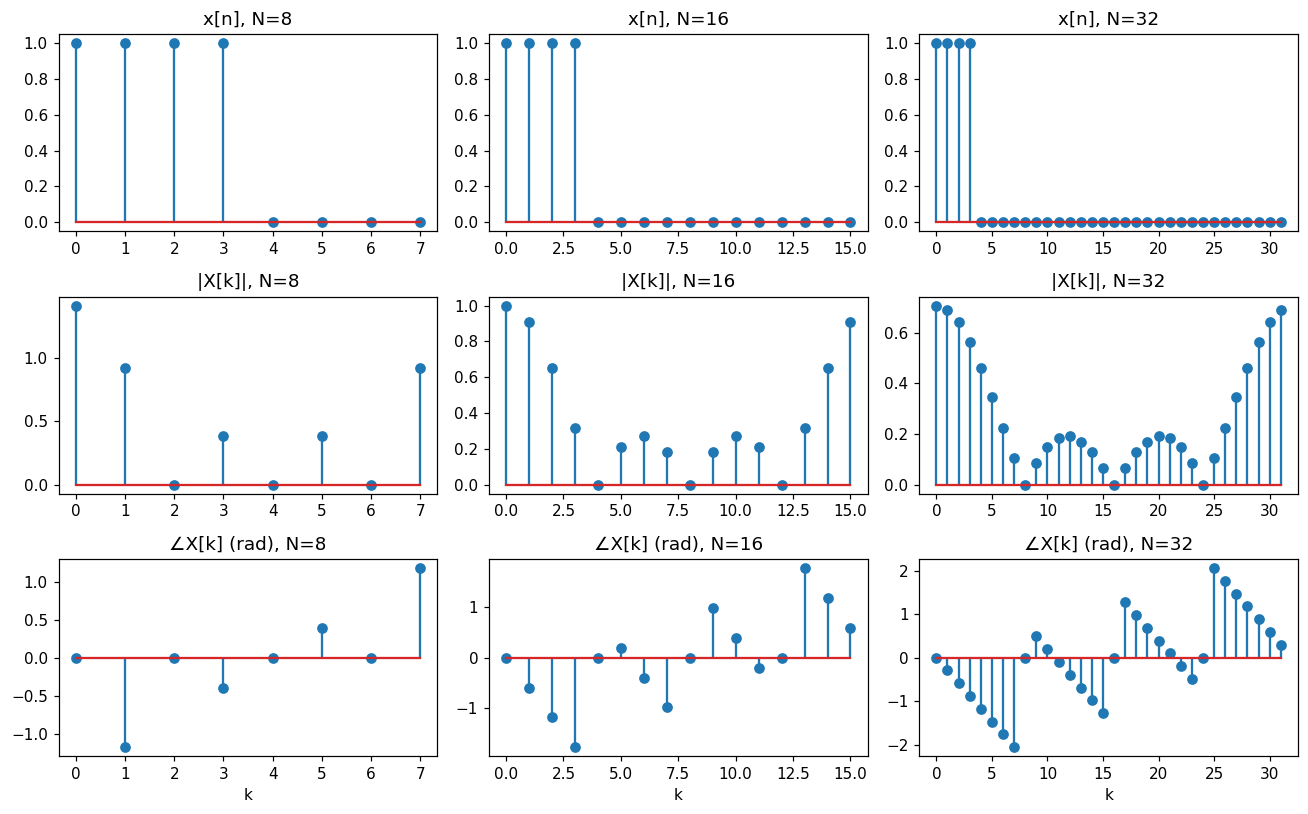

In [ ]:
fig, ax = plt.subplots(3, 3, figsize=(12, 7.5))
for j, N in enumerate([8, 16, 32]):
    x = np.zeros(N); x[:4] = 1; X = dft(x)
    ph = np.where(np.abs(X) < 1e-10, 0.0, np.angle(X))   # fase indefinida onde |X| ~ 0 = plota 0
    ax[0,j].stem(x);           ax[0,j].set_title(f"x[n], N={N}")
    ax[1,j].stem(np.abs(X));   ax[1,j].set_title(f"|X[k]|, N={N}")
    ax[2,j].stem(ph);          ax[2,j].set_title(f"∠X[k] (rad), N={N}"); ax[2,j].set_xlabel("k")
plt.tight_layout(); plt.show()

**Validação contra o NumPy** e **propriedades da tabela**:

In [ ]:
xr = rng.standard_normal(64) + 1j*rng.standard_normal(64)
print("erro DFT vs numpy :", np.max(np.abs(dft(xr) - np.fft.fft(xr)/8)))
print("erro IDFT(DFT(x)) :", np.max(np.abs(idft(dft(xr)) - xr)))
errs = run_all_properties()
pd.DataFrame({"Propriedade": errs.keys(), "Erro máx.": [f"{v:.1e}" for v in errs.values()],
              "OK": ["✔" if v < 1e-9 else "✘" for v in errs.values()]})

erro DFT vs numpy : 1.2560739669470201e-15
erro IDFT(DFT(x)) : 1.3426356273935429e-15


,Propriedade,Erro máx.,OK
0,Linearidade,2.0e-15,✔
1,Deslocamento no tempo,6.5e-15,✔
2,Deslocamento na frequência,8.1e-16,✔
3,Reversão temporal,4.4e-16,✔
4,Conjugação complexa,8.0e-16,✔
5,Convolução circular no tempo,7.1e-15,✔
6,Multiplicação ponto a ponto,1.9e-15,✔
7,Parseval,2.4e-15,✔
8,Periodicidade,1.5e-14,✔
9,Simetria para sinais reais,6.3e-16,✔


## Tarefa 2 — Convolução linear via convolução circular
A circular de tamanho $N$ coincide com a linear se e somente se $N\ge K+L-1$:  $y=\mathrm{IDFT}\{\sqrt N\,X[k]H[k]\}$.

max|linear direta − linear via DFT| = 8.881784197001252e-16
max|np.convolve  − linear via DFT| = 1.1102230246251565e-15
max|linear − circular N=5| (5 primeiras) = 1.1175287178377615  <- aliasing


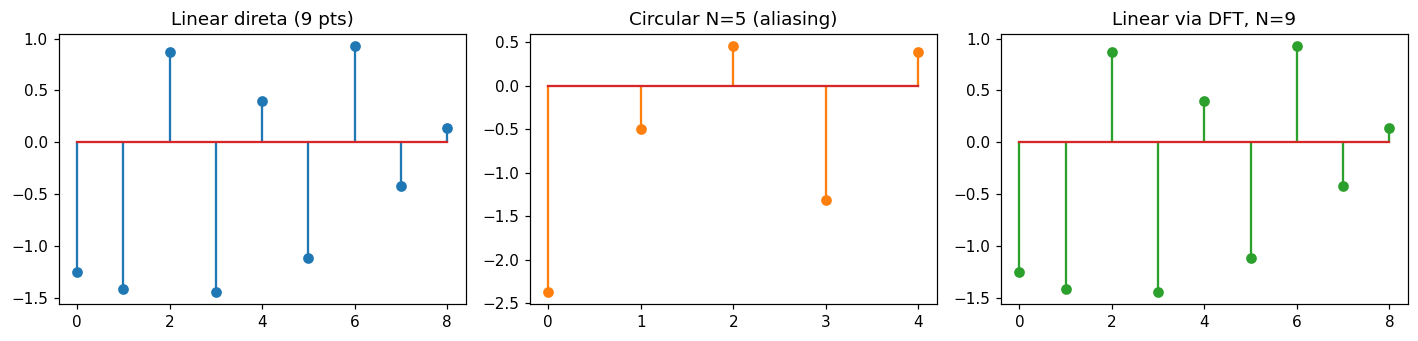

In [ ]:
L = K = 5
x, h = rng.standard_normal(L), rng.standard_normal(K)
y_lin, y_circ, y_dft = linear_convolution(x, h).real, circular_convolution(x, h).real, linear_convolution_dft(x, h).real
print("max|linear direta − linear via DFT| =", np.max(np.abs(y_lin - y_dft)))
print("max|np.convolve  − linear via DFT| =", np.max(np.abs(np.convolve(x, h) - y_dft)))
print("max|linear − circular N=5| (5 primeiras) =", np.max(np.abs(y_lin[:5] - y_circ)), " <- aliasing")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].stem(y_lin);  ax[0].set_title("Linear direta (9 pts)")
ax[1].stem(y_circ, linefmt="C1-", markerfmt="C1o"); ax[1].set_title("Circular N=5 (aliasing)")
ax[2].stem(y_dft, linefmt="C2-", markerfmt="C2o");  ax[2].set_title("Linear via DFT, N=9")
plt.tight_layout(); plt.show()

## Tarefa 3 — Overlap-and-add e overlap-and-save
Teste: média móvel de $K=31$ pontos sobre um sinal ruidoso de 1000 amostras.

,Overlap-add,Overlap-save
N_DFT,,
32,4.4e-16,6.7e-16
64,5.6e-16,8.3e-16
128,5.7e-16,5.9e-16
256,8.2e-16,6.4e-16


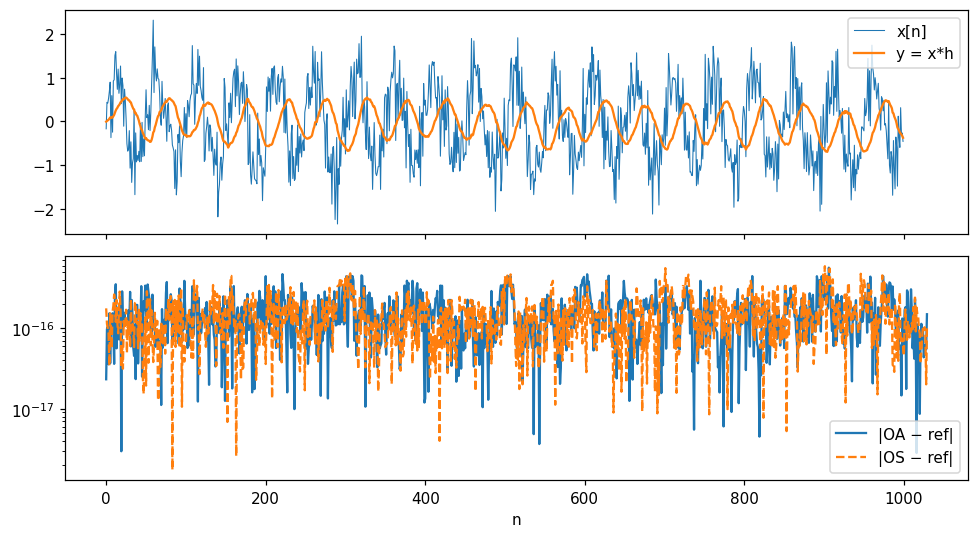

In [ ]:
L, K = 1000, 31
x = np.sin(2*np.pi*0.02*np.arange(L)) + 0.5*rng.standard_normal(L); h = np.ones(K)/K; ref = np.convolve(x, h)
err = lambda y: np.max(np.abs(y - ref))
rows = [{"N_DFT": n, "Overlap-add": err(overlap_add(x, h, n)), "Overlap-save": err(overlap_save(x, h, n))}
        for n in [32, 64, 128, 256]]
display(pd.DataFrame(rows).set_index("N_DFT").map(lambda v: f"{v:.1e}"))
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
ax[0].plot(x, lw=.7, label="x[n]"); ax[0].plot(ref[:L], label="y = x*h"); ax[0].legend()
ax[1].semilogy(np.abs(overlap_add(x, h, 128) - ref) + 1e-18, label="|OA − ref|")
ax[1].semilogy(np.abs(overlap_save(x, h, 128) - ref) + 1e-18, "--", label="|OS − ref|")
ax[1].set_xlabel("n"); ax[1].legend(); plt.tight_layout(); plt.show()

## Tarefa 4 — FFT radix-2 e comparação com a DFT
$X[k]=X_e[k]+W_N^kX_o[k]$, $X[k+N/2]=X_e[k]-W_N^kX_o[k]$. Custo $N\log_2N$ contra $N^2$.

In [ ]:
print("Reversão de bits  N=4:", bit_reversal_indices(4), "  N=8:", bit_reversal_indices(8))
x = rng.standard_normal(256) + 1j*rng.standard_normal(256)
print("erro FFT vs numpy:", np.max(np.abs(fft_iterative(x) - np.fft.fft(x)/16)))

Reversão de bits  N=4: [0 2 1 3]   N=8: [0 4 2 6 1 5 3 7]
erro FFT vs numpy: 2.220446049250313e-15


**Benchmark** (DFT com laços limitada a N ≤ 1024 e DFT matricial a N ≤ 4096 por tempo/memória):

,dft_loop,dft_matriz,fft_iterativa,numpy_fft
N,,,,
8,9.09e-05,3.88e-05,7.27e-05,1.35e-05
16,1.67e-04,5.62e-05,1.28e-04,1.33e-05
32,4.58e-04,7.77e-05,1.16e-04,1.38e-05
64,1.57e-03,3.26e-04,4.48e-04,2.24e-05
128,1.25e-02,1.60e-03,9.45e-04,2.46e-05
256,3.99e-02,4.38e-03,2.13e-03,3.27e-05
512,9.47e-02,1.57e-02,4.52e-03,3.61e-05
1024,3.81e-01,5.91e-02,9.93e-03,4.66e-05
2048,—,3.04e-01,1.99e-02,7.79e-05


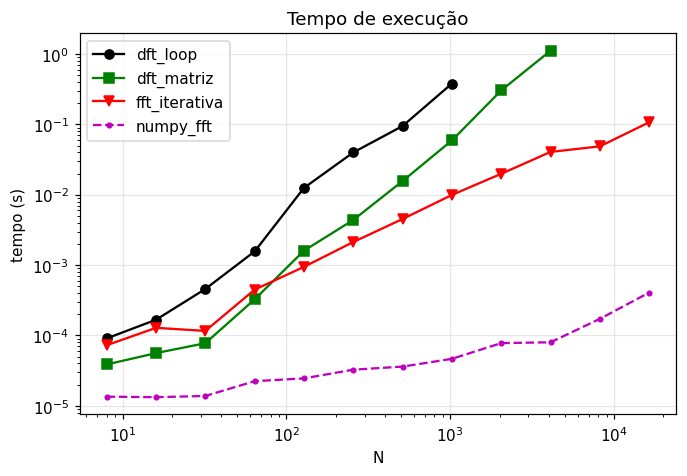

N=1024: DFT (laços) é 38x mais lenta que a FFT iterativa


In [ ]:
def best_time(f, x, reps=3):
    t = []
    for _ in range(reps): t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return min(t)
methods = {"dft_loop": (dft_loop, 1024), "dft_matriz": (dft, 4096), "fft_iterativa": (fft_iterative, 1e9),
           "numpy_fft": (lambda v: np.fft.fft(v)/np.sqrt(len(v)), 1e9)}
rows = []
for N in 2**np.arange(3, 15):
    x = rng.standard_normal(N) + 1j*rng.standard_normal(N)
    rows.append({"N": N, **{m: best_time(f, x) if N <= nmax else np.nan for m, (f, nmax) in methods.items()}})
bench = pd.DataFrame(rows).set_index("N")
display(bench.map(lambda v: "—" if np.isnan(v) else f"{v:.2e}"))

plt.figure(figsize=(7, 4.5))
for m, st in zip(methods, ["ko-", "gs-", "rv-", "m.--"]): plt.loglog(bench.index, bench[m], st, label=m)
plt.xlabel("N"); plt.ylabel("tempo (s)"); plt.title("Tempo de execução"); plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"N=1024: DFT (laços) é {bench.loc[1024,'dft_loop']/bench.loc[1024,'fft_iterativa']:.0f}x mais lenta que a FFT iterativa")

In [ ]:
for N in [8, 64, 512, 4096]:
    x = rng.standard_normal(N) + 1j*rng.standard_normal(N)
    print(f"N={N}: erro máx. FFT vs DFT = {np.max(np.abs(fft_iterative(x) - dft(x))):.1e}")

N=8: erro máx. FFT vs DFT = 2.5e-16
N=64: erro máx. FFT vs DFT = 1.3e-15
N=512: erro máx. FFT vs DFT = 2.7e-15
N=4096: erro máx. FFT vs DFT = 4.2e-15
